# Tutorial #
Welcome to my code! This notebook is meant to be an introduction into the computation of Relative Periodic Orbits (RPOs) in 2D magnetohydrodynamics (MHD).

## MHD ##
The magnetohydrodynamics (MHD) equations considered here are incompressible, so we have two constraints
$$
\nabla \cdot {\bf u} = 0,
$$
$$
\nabla \cdot {\bf B} = 0.
$$
These constraints are preserved by the MHD equations of motion
$$
\partial_t {\bf u} + \nabla \cdot ( {\bf u u} - {\bf BB}) + \nabla \tilde{p} = \nu \nabla^2 {\bf u} + {\bf f},
$$
$$
\partial_t {\bf B} + \nabla \cdot ({\bf uB} - {\bf Bu}) = \eta \nabla^2 {\bf B},
$$
where $\tilde{p}$ is the total pressure, $\nu$ is the kinematic viscosity, ${\bf f}$ is the body forcing, and $\eta$ is the resistivity. To make our lives easier, I wrote this code to solve the equations in the vorticity formulation, in which I evolve the curls of these fields.
$$
\omega = \partial_x u_y - \partial_y u_x,
$$
$$ 
j = \partial_x B_y - \partial_y B_x.
$$
The equations of motion are fairly simple compared to the vector formulation. If you are new to this method, I encourage you to work out these equations of motion yourself.
$$
\partial_t \omega + {\bf u} \cdot \nabla \omega - {\bf B} \cdot \nabla j = \nu \nabla^2 \omega + f_\omega,
$$
$$
\partial_t j + \nabla^2 ( u_x B_y - B_x u_y ) = \eta \nabla^2 j,
$$
where $f_\omega = \partial_x f_y - \partial_y f_x$ is the vorticity forcing. This is now a pressure-free formulation. For periodic boundary conditions, mapping from $\omega \rightarrow {\bf u}$ and $j \rightarrow {\bf B}$ is trivial in Fourier space. This makes this formulation rather attractive. I have focused on doubly periodic domains with $x,y\in[0,2\pi]^2$.


## Environment Setup ##
This repo uses [uv](https://docs.astral.sh/uv/) for package management. From the repo root (one directory up from this notebook), run in a terminal:
```bash
uv sync            # CPU
uv sync --extra cuda   # if you have an NVIDIA GPU + CUDA 12 drivers
```
Then launch this notebook with `uv run jupyter lab` (or point your existing Jupyter kernel at `.venv/bin/python`).

In [1]:
# confirm jax is installed correctly and see what devices it sees.
# If you installed `uv sync --extra cuda` on a GPU machine, you should see a CudaDevice below.
# If you see only CpuDevice, jax is falling back to CPU (check your CUDA drivers / the install extra used).
import jax
print("jax version:", jax.__version__)
print("Devices:", jax.devices())
print("Default backend:", jax.default_backend())

jax version: 0.12.0


Devices: [CudaDevice(id=0)]
Default backend: gpu


Jax is using [CudaDevice(id=0)]



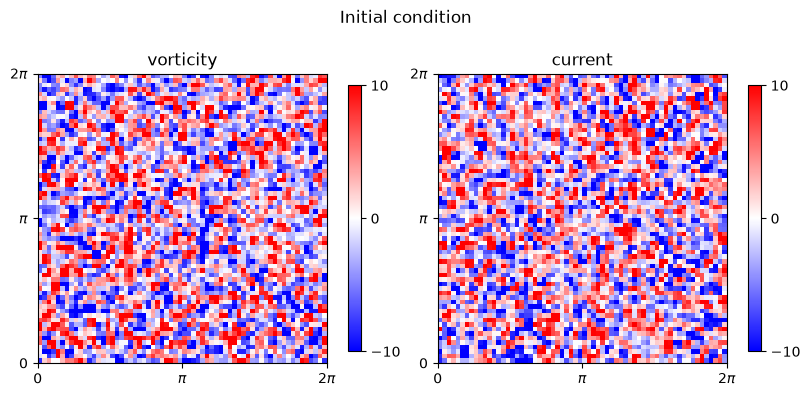

In [2]:
%load_ext autoreload
%autoreload 2

import lib.mhd_jax as mhd_jax
import lib.utils as utils

n    = 64              # grid resolution (n x n)
nu   = 1/20             # fluid dissipation
eta  = 1/20             # magnetic dissipation
b0   = [0.0, 0.1]       # mean magnetic field
u0   = [0.0, 0.0]       # mean flow field
seed = 1234           # RNG seed for the random initial condition

# Forcing is specified as a string defining a lambda(x,y) -> vorticity forcing.
# Here: Kolmogorov forcing at wavenumber 4.
forcing_str = "lambda x,y : -4*jnp.cos(4*y)"

###############################
# Everything else (grid construction, dealiasing, random field generation)
# is handled for you inside utils.initialize_system
###############################
f0, param_dict = utils.initialize_system(n, nu, eta, b0, u0, seed, forcing_str)

figure, axis = mhd_jax.vis(f0, in_spectral=False, title="Initial condition")

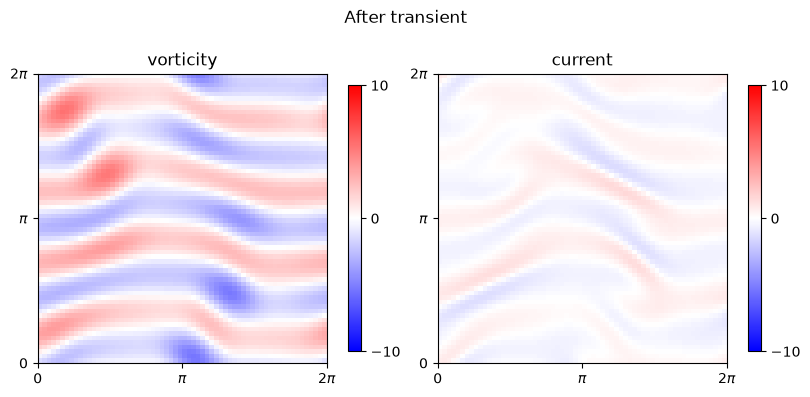

In [3]:
# Evolve a transient so our random initial condition relaxes onto the turbulent attractor.

dt = 1/128            # timestep
transient_time = 24.0  # total time to integrate the transient for

f = utils.evolve_transient(f0, param_dict, dt, transient_time)

figure, axis = mhd_jax.vis(f, in_spectral=True, title="After transient")

In [4]:
# Now that we have a sensible initial condition, integrate to build a timeseries
# and compute a recurrence diagram -- near-recurrences make good RPO guesses.

dt = 1/128
micro_steps = 16   # timesteps between saving
macro_steps = 256  # number of saved states

fs, dist = utils.generate_turbulent_trajectory(f, param_dict, dt, macro_steps, micro_steps)

Generating 256 steps of turbulence took 3.368889331817627 seconds.


Recurrence diagram computed in 1.837836742401123 seconds


Wrote 256 frames to figures/turbulence.gif


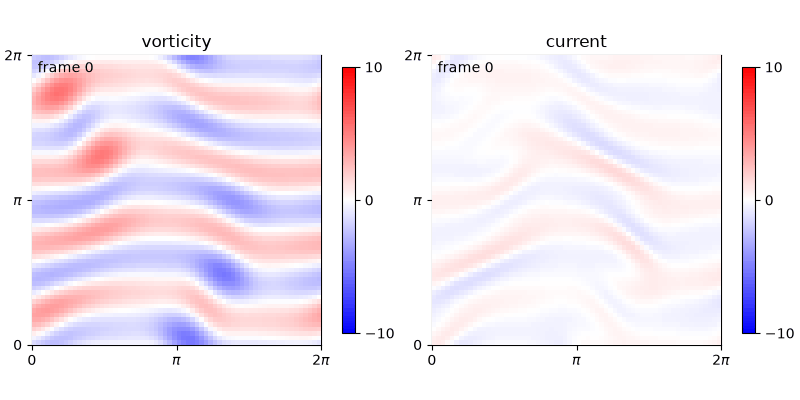

In [5]:
from IPython.display import Image

gif_path = utils.make_gif(fs, filename="figures/turbulence.gif", fps=8)
Image(filename=gif_path)

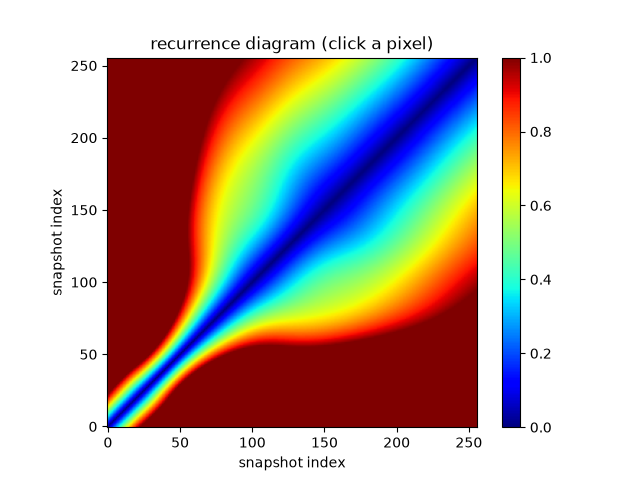

In [6]:
%matplotlib widget
# Bright streaks off the diagonal indicate near-recurrences -- good candidates for RPO guesses.
figure = utils.plot_recurrence_diagram(dist)

In [7]:
#Now we can make a guess at a recurrence. Zoom into the recurrence diagram near the
#diagonal: a dark pixel a short distance off the diagonal is a near-recurrence, a good
#RPO guess. Here we picked one by hand at i=152, j=170 this way.

idx = [152, 170]

#Append timestepping information as well
param_dict.update( {'dt': dt, 'ministeps': micro_steps, 'steps': macro_steps} )
turb_dict = {'fs': fs}
input_dict, param_dict = utils.create_state_from_turb(turb_dict, idx, param_dict)

Best symmetry found is (0.0, 0, False)


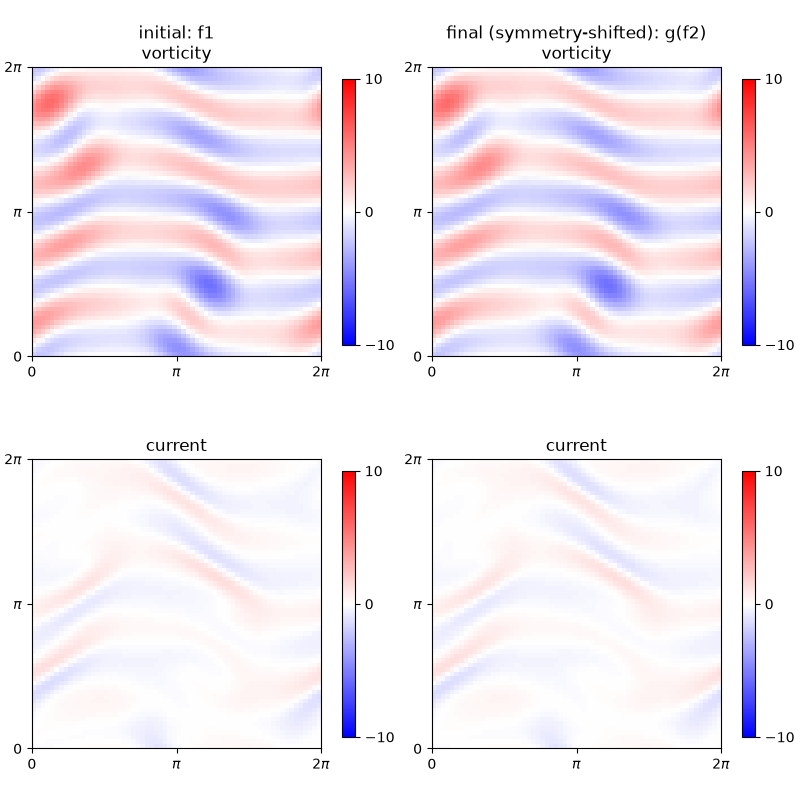

In [8]:
# Sanity check the guess: the initial snapshot and the symmetry-shifted final
# snapshot should look nearly identical if this is a good RPO candidate.
figure, axis = utils.compare_initial_final(turb_dict, idx, input_dict, param_dict)

In [9]:
#For fixed timestep solvers, we need to define parameters for checkpointing.
ministeps = 8
assert( param_dict['steps'] % ministeps == 0 )
param_dict.update({"ministeps": ministeps, "num_checkpoints": param_dict['steps']//ministeps })

maxit = 400          # number of ADAM steps
lr = 2e-2            # ADAM learning rate
save_every = 400     # checkpoint to disk every this many steps
min_abs_T = 0.3      # floor |T| away from 0 -- the loss has an exact minimum at T=0
                     # for any field (zero-duration integration is trivially the
                     # identity), so unconstrained descent would collapse there.

input_dict, history = utils.run_adjoint_descent(input_dict, param_dict, maxit=maxit, lr=lr,
                                                  save_every=save_every, min_abs_T=min_abs_T)

0: loss=0.007050, walltime=3.036, T=2.230, sx=-0.020


1: loss=0.003758, walltime=0.554, T=2.221, sx=-0.027


2: loss=0.005137, walltime=0.515, T=2.222, sx=-0.024


3: loss=0.002469, walltime=0.520, T=2.226, sx=-0.018


4: loss=0.001115, walltime=0.517, T=2.228, sx=-0.014


...

395: loss=0.000017, walltime=0.521, T=1.894, sx=-0.032


396: loss=0.000017, walltime=0.518, T=1.893, sx=-0.032


397: loss=0.000017, walltime=0.520, T=1.892, sx=-0.032


398: loss=0.000017, walltime=0.517, T=1.891, sx=-0.032


399: loss=0.000017, walltime=0.521, T=1.890, sx=-0.032


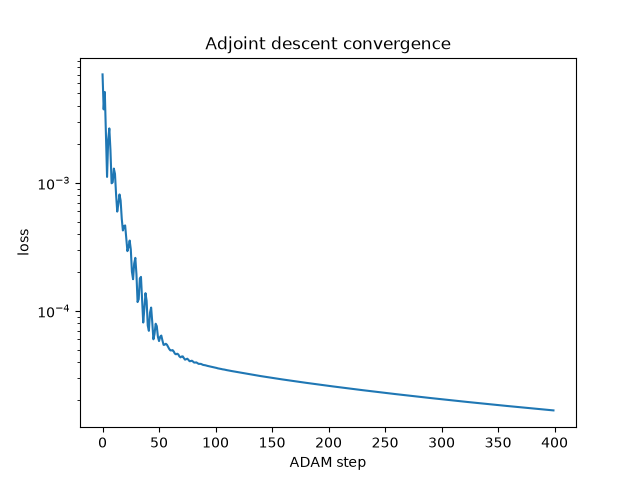

In [10]:
import matplotlib.pyplot as plt
plt.figure()
plt.semilogy(history)
plt.xlabel("ADAM step")
plt.ylabel("loss")
plt.title("Adjoint descent convergence")
plt.show()

## Newton vs Gauss-Newton ##
Adjoint descent gets us close, but convergence slows down a lot near the solution. We now fine-tune with Newton-GMRES.

Both variants solve the same Newton step with GMRES, computing Jacobian actions via `jax.jvp`. The only difference is `use_transpose`:
- **Newton** (`use_transpose=False`): solve $Js = -f$ directly.
- **Gauss-Newton** (`use_transpose=True`): precondition GMRES with the Jacobian transpose, equivalent to solving the normal equations $(J^TJ)s = -J^Tf$.

Gauss-Newton typically needs far fewer Krylov directions per step and tolerates larger steps, at the cost of being a descent method (it can in principle stall at a local minimum of $|f|^2$ rather than a true root).

In [11]:
import copy

# Load the most recently saved adjoint-descent checkpoint as our starting guess.
newton_input_dict, newton_param_dict = utils.load_latest_checkpoint("temp_data/adjoint_descent")

###############################
# Newton / Gauss-Newton parameters -- the only things you need to touch
###############################

maxit = 15    # number of Newton/Gauss-Newton steps
inner = 8     # GMRES Krylov subspace dimension -- small on purpose, to show
              # Gauss-Newton tolerating it while plain Newton struggles
mode = "RK4"  # timestepping scheme used inside the objective
min_abs_T = 0.3  # same trivial-root issue as adjoint descent -- GN/Newton's own
                 # root-finding can also walk into the T=0 solution, so floor it here too

# Run both methods from identical copies of the same starting guess.
newton_out, newton_history = utils.run_newton(
    copy.deepcopy(newton_input_dict), copy.deepcopy(newton_param_dict),
    use_transpose=False, maxit=maxit, inner=inner, mode=mode, min_abs_T=min_abs_T)

gn_out, gn_history = utils.run_newton(
    copy.deepcopy(newton_input_dict), copy.deepcopy(newton_param_dict),
    use_transpose=True, maxit=maxit, inner=inner, mode=mode, min_abs_T=min_abs_T)

Loading temp_data/adjoint_descent/399.npz


float64


Evaluating objective: 0.194 seconds
Evaluating Jacobian: 0.364 seconds


0: rel_err=3.156e-03, |f|=3.698e-01, gmres_rel_res=9.825e-01, T=1.890, sx=-0.032


1: rel_err=3.095e-03, |f|=3.627e-01, gmres_rel_res=9.993e-01, T=1.890, sx=-0.032


...

10: rel_err=5.923e-03, |f|=6.940e-01, gmres_rel_res=4.297e-05, T=0.300, sx=-0.002


11: rel_err=5.504e-03, |f|=6.449e-01, gmres_rel_res=4.538e-05, T=0.300, sx=-0.002


12: rel_err=5.607e-03, |f|=6.570e-01, gmres_rel_res=4.468e-05, T=0.300, sx=-0.002


13: rel_err=5.597e-03, |f|=6.558e-01, gmres_rel_res=4.489e-05, T=0.300, sx=-0.002


14: rel_err=5.568e-03, |f|=6.524e-01, gmres_rel_res=4.543e-05, T=0.300, sx=-0.002


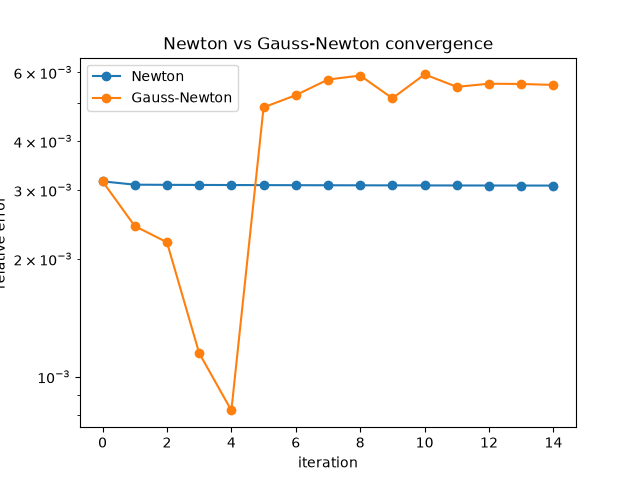

In [12]:
figure = utils.plot_newton_comparison([newton_history, gn_history], ["Newton", "Gauss-Newton"])

## Finishing off with Newton ##
Gauss-Newton is a descent method on $|f|^2$, so it stalls before reaching machine precision. Once we're close, switch to plain Newton with a much larger Krylov subspace to finish the job -- true Newton has quadratic local convergence near the root.

In [13]:
import copy

###############################
# Finishing Newton -- the only parameters you need to touch
###############################

maxit = 15    # should converge fast once close to the root
inner = 64    # large Krylov subspace for an accurate Newton step
mode = "RK4"  # timestepping scheme used inside the objective
min_abs_T = 0.3

converged_out, converged_history = utils.run_newton(
    copy.deepcopy(gn_out), copy.deepcopy(newton_param_dict),
    use_transpose=False, maxit=maxit, inner=inner, mode=mode, min_abs_T=min_abs_T)

Evaluating objective: 0.196 seconds
Evaluating Jacobian: 0.37 seconds


0: rel_err=5.524e-03, |f|=6.472e-01, gmres_rel_res=1.978e-02, T=0.303, sx=-0.003


1: rel_err=4.395e-03, |f|=5.129e-01, gmres_rel_res=1.396e-02, T=0.300, sx=-0.004


2: rel_err=3.153e-03, |f|=3.652e-01, gmres_rel_res=3.082e-02, T=0.300, sx=-0.005


3: rel_err=1.976e-03, |f|=2.278e-01, gmres_rel_res=8.792e-02, T=0.305, sx=-0.006


...

10: rel_err=1.855e-04, |f|=2.141e-02, gmres_rel_res=8.803e-01, T=0.305, sx=-0.006


11: rel_err=1.817e-04, |f|=2.097e-02, gmres_rel_res=9.428e-01, T=0.305, sx=-0.006


12: rel_err=1.721e-04, |f|=1.986e-02, gmres_rel_res=9.638e-01, T=0.305, sx=-0.006


13: rel_err=1.712e-04, |f|=1.977e-02, gmres_rel_res=9.919e-01, T=0.305, sx=-0.006


14: rel_err=1.710e-04, |f|=1.973e-02, gmres_rel_res=9.888e-01, T=0.305, sx=-0.006


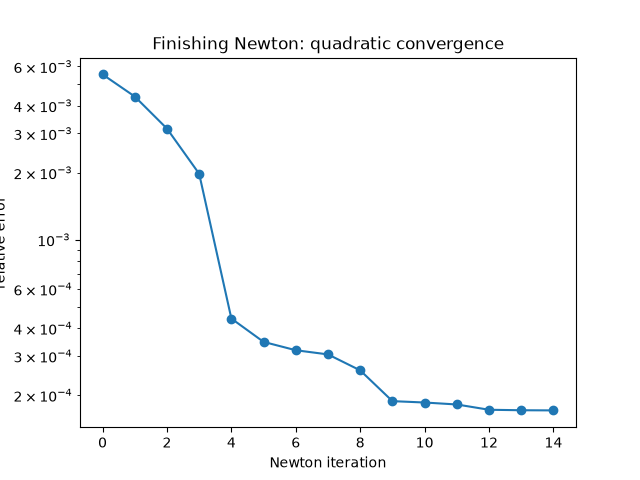

In [14]:
import matplotlib.pyplot as plt
plt.figure()
plt.semilogy([h['rel_err'] for h in converged_history], marker='o')
plt.xlabel("Newton iteration")
plt.ylabel("relative error")
plt.title("Finishing Newton: quadratic convergence")
plt.show()

In [15]:
# Save all three final states for later use (e.g. further refinement, Floquet analysis, visualization).
utils.save_state("temp_data/newton/newton_final.npz", newton_out, newton_param_dict)
utils.save_state("temp_data/newton/gauss_newton_final.npz", gn_out, newton_param_dict)
utils.save_state("temp_data/newton/converged_final.npz", converged_out, newton_param_dict)

Saved temp_data/newton/newton_final.npz
Saved temp_data/newton/gauss_newton_final.npz
Saved temp_data/newton/converged_final.npz


Wrote 128 frames to figures/rpo.gif


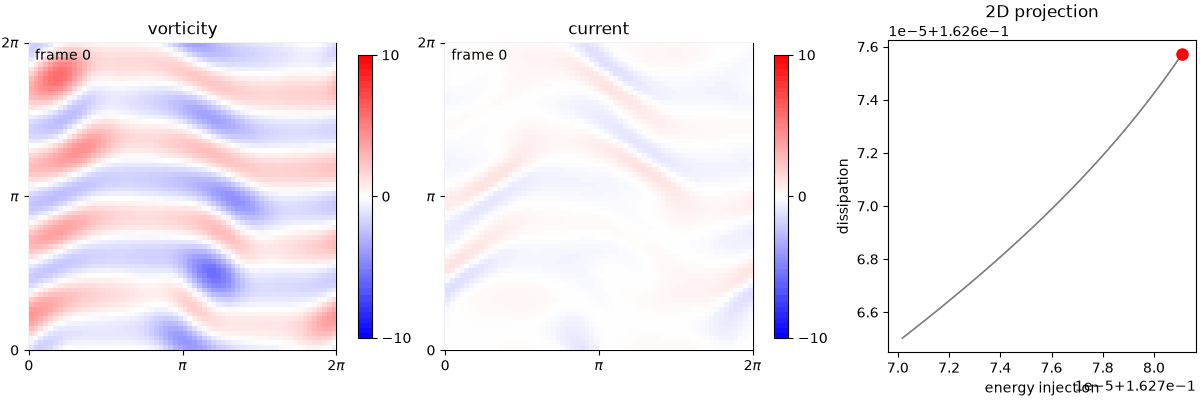

In [16]:
from IPython.display import Image

# Animate the fully-converged RPO over one period, alongside a 2D projection of the
# trajectory onto (energy injection, dissipation).
gif_path = utils.animate_rpo(converged_out, newton_param_dict, filename="figures/rpo.gif", steps=128, fps=16)
Image(filename=gif_path)